<a href="https://colab.research.google.com/github/dzamaadam-afk/analyzy/blob/main/Analyza_nosnikov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

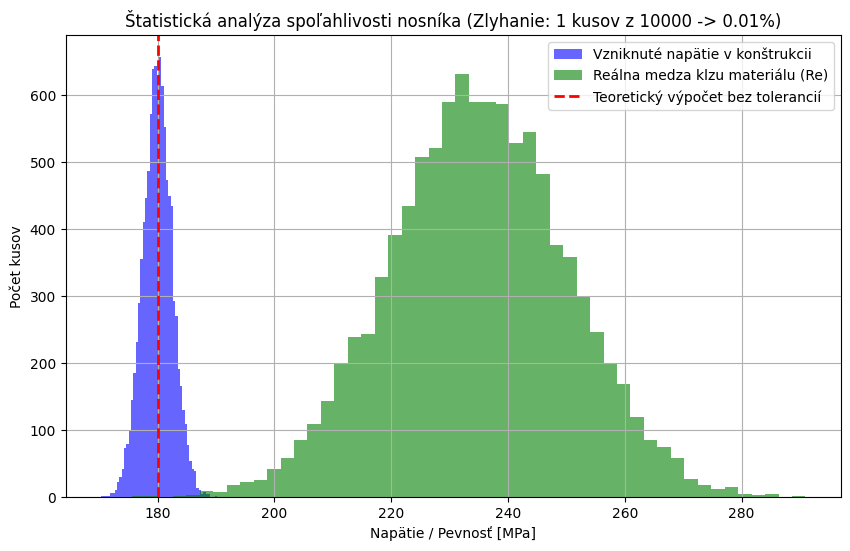

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. PARAMETRE SIMULÁCIE (Metóda Monte Carlo)
pocet_nosnikov = 10000  # Nasimulujeme 10-tisíc reálnych kusov z výroby
dlzka_nosnika = 2.0  # metre
sila_zatazenia = 7500  # 7,5 kN pôsobiacich na konci nosníka

# 2. ŠTATISTICKÉ ROZDELENIE VLASTNOSTÍ (Gaussovo rozdelenie zo strojárskych tabuliek)
# Medza klzu ocele (stredná hodnota 235 MPa, odchýlka 15 MPa kvôli kvalite materiálu)
Re = np.random.normal(235e6, 15e6, pocet_nosnikov)

# Rozmery prierezu nosníka (hrúbka plechu s toleranciou z výroby +/- 0.5 mm)
vyska = np.random.normal(0.100, 0.0005, pocet_nosnikov)  # stredná výška 100 mm
sirka = np.random.normal(0.050, 0.0005, pocet_nosnikov)  # stredná šírka 50 mm

# 3. PEVNOSTNÝ VÝPOČET (Klasická pružnosť a pevnosť zo SjF)
# Maximálny ohybový moment pre konzolu: M = F * L
M_max = sila_zatazenia * dlzka_nosnika

# Prierezový modul v ohybe: Wo = (b * h^2) / 6
Wo = (sirka * (vyska**2)) / 6

# Maximálne napätie v nosníku: sigma = M / Wo
maximalne_napatie = M_max / Wo

# 4. VYHODNOTENIE: Ktoré nosníky sa plasticky zdeformujú? (Napätie > Pevnosť)
zlyhane_nosniky = maximalne_napatie > Re
pocet_zlyhani = np.sum(zlyhane_nosniky)
percento_zlyhani = (pocet_zlyhani / pocet_nosnikov) * 100

# 5. VYKRESLENIE ŠTATISTICKÉHO HISTOGRAMU
plt.figure(figsize=(10, 6))
plt.hist(maximalne_napatie / 1e6, bins=50, alpha=0.6, color='blue', label='Vzniknuté napätie v konštrukcii')
plt.hist(Re / 1e6, bins=50, alpha=0.6, color='green', label='Reálna medza klzu materiálu (Re)')

plt.axvline(M_max / ((0.050 * (0.100**2)) / 6) / 1e6, color='red', linestyle='--', linewidth=2,
            label='Teoretický výpočet bez tolerancií')

plt.title(f"Štatistická analýza spoľahlivosti nosníka (Zlyhanie: {pocet_zlyhani} kusov z {pocet_nosnikov} -> {percento_zlyhani:.2f}%)")
plt.xlabel("Napätie / Pevnosť [MPa]")
plt.ylabel("Počet kusov")
plt.legend()
plt.grid(True)
plt.show()